# 微调入门：让预训练 ResNet18 适应蚂蚁/蜜蜂分类

课程里已经做过“从数据训练模型”和“加载 ONNX 模型预测”。这次把二者连接起来：**加载已有参数，再用带标签的数据更新部分参数**。

| 阶段 | 哪些参数会变 | 学习目标 |
|---|---|---|
| 预训练模型 + 新分类层 | 此时还没训练；分类层随机初始化 | 输出由 ImageNet 的 1000 类变成 2 类 |
| 阶段一：固定特征提取器 | 只更新新分类层 fc | 复用已有视觉特征 |
| 阶段二：微调 | 更新预训练的 layer4 和分类层 | 让已有特征适应当前任务 |

微调也是训练。区别在于参数起点和更新范围。只替换 labels、调用 eval() 或预测，不会改变模型知识。

本例采用 PyTorch 可训练网络；课程里的 ONNX 主要用于推理。最终权重仍保存在模型对象里，再写入文件。

## 1. 环境和实验设置

先按同目录 README 安装依赖，再选择对应 Python 内核。从本目录或仓库根目录运行均可。

默认 CPU、每类 32 张训练图、每阶段 2 个 epoch，用于快速观察机制；这不表示模型已经充分收敛。一个 epoch 是把当前训练集遍历一遍，一个 batch 才对应一次梯度更新。随机种子帮助复现，同一数字不保证跨设备和依赖版本完全相同的结果。

In [1]:
import copy
import json
import os
import platform
import random
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from PIL import Image
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from torchvision.datasets.utils import download_and_extract_archive
from torchvision.transforms import InterpolationMode

SEED = 42
BATCH_SIZE = 16
TRAIN_PER_CLASS = 32  # 改为 None 使用全部训练图片
HEAD_EPOCHS = 2
FINE_TUNE_EPOCHS = 2
device = torch.device("cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))

EXAMPLE_DIR = Path("扩展练习/图像分类微调")
if not EXAMPLE_DIR.is_dir():
    EXAMPLE_DIR = Path(".")
DATA_DIR = EXAMPLE_DIR / "data"
OUTPUT_DIR = EXAMPLE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version(), "Environment:", Path(sys.prefix).name)
print("Architecture:", platform.machine())
print("PyTorch:", torch.__version__, "Torchvision:", torchvision.__version__)
print("Device:", device)


Python: 3.12.14 Environment: .venv
Architecture: arm64
PyTorch: 2.10.0 Torchvision: 0.25.0
Device: cpu


## 2. 获取数据，确定标签和划分

使用 [PyTorch 官方教程的图片包](https://download.pytorch.org/tutorial/hymenoptera_data.zip)。目录名 ants/bees 就是分类标签。ImageFolder 按类目录名排序生成编号，实际映射由 class_to_idx 给出。

保留原 train 目录作训练数据；将原 val 目录分层拆成验证集和测试集。验证集用于选择两个阶段的候选模型，测试集留到最后。

**边界说明：**官方图片包是 ImageNet 的小子集，预训练权重也来自 ImageNet。下述测试集没有参加本次微调，但不能保证没有参加过上游预训练；这里用于学习完整流程，不是严格的预训练未见数据基准。

In [2]:
DATA_URL = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
DATASET_DIR = DATA_DIR / "hymenoptera_data"

if not (DATASET_DIR / "train").is_dir():
    download_and_extract_archive(DATA_URL, download_root=str(DATA_DIR))

weights = models.ResNet18_Weights.IMAGENET1K_V1
preprocess = weights.transforms()

# 只对训练图片增加随机翻转；尺寸和数值处理复用权重自带的规则。
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    preprocess,
])
train_data = datasets.ImageFolder(DATASET_DIR / "train", transform=train_transform)
evaluation_data = datasets.ImageFolder(DATASET_DIR / "val", transform=preprocess)
class_names = train_data.classes
assert train_data.class_to_idx == evaluation_data.class_to_idx

rng = np.random.default_rng(SEED)
train_indices = []
for class_index in range(len(class_names)):
    indices = np.flatnonzero(np.array(train_data.targets) == class_index)
    rng.shuffle(indices)
    if TRAIN_PER_CLASS is not None:
        indices = indices[:TRAIN_PER_CLASS]
    train_indices.extend(indices.tolist())

val_indices, test_indices = train_test_split(
    np.arange(len(evaluation_data)),
    test_size=0.5,
    random_state=SEED,
    stratify=evaluation_data.targets,
)

split_datasets = {
    "train": Subset(train_data, train_indices),
    "val": Subset(evaluation_data, val_indices.tolist()),
    "test": Subset(evaluation_data, test_indices.tolist()),
}
loaders = {
    name: DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=(name == "train"),
        num_workers=0,
        generator=torch.Generator().manual_seed(SEED),
    )
    for name, dataset in split_datasets.items()
}

split_manifest = {
    name: [
        str(Path(dataset.dataset.samples[i][0]).relative_to(DATASET_DIR))
        for i in dataset.indices
    ]
    for name, dataset in split_datasets.items()
}
assert set(split_manifest["train"]).isdisjoint(split_manifest["val"])
assert set(split_manifest["train"]).isdisjoint(split_manifest["test"])
assert set(split_manifest["val"]).isdisjoint(split_manifest["test"])

print("Labels:", train_data.class_to_idx)
print("Samples:", {name: len(dataset) for name, dataset in split_datasets.items()})
print("Preprocessing:", preprocess)


Labels: {'ants': 0, 'bees': 1}
Samples: {'train': 64, 'val': 76, 'test': 77}
Preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


DataLoader 将一批图片和标签组织成张量。图片形状是 (N, 3, 224, 224)，标签形状是 (N,)；N 是这一批实际样本数，最后一批可能小于 16。标签是整数编号，不是文本。

下面显示原图。训练时的随机翻转和权重自带的缩放、裁剪、归一化会在读取样本时自动执行。

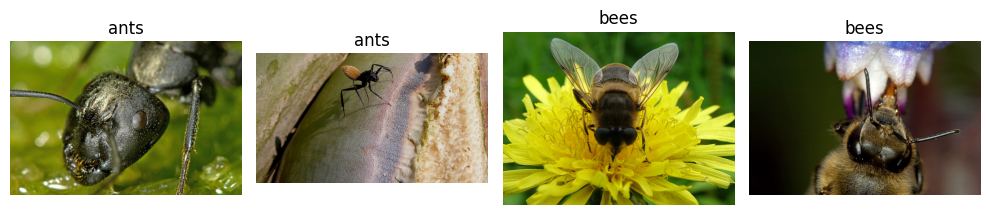

Batch images: torch.Size([16, 3, 224, 224]) torch.float32
Batch labels: torch.Size([16]) torch.int64


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
preview_indices = train_indices[:2] + train_indices[-2:]
for axis, index in zip(axes, preview_indices):
    image_path, label = train_data.samples[index]
    with Image.open(image_path) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(class_names[label])
    axis.axis("off")
plt.tight_layout()
plt.show()

images, labels = next(iter(loaders["train"]))
print("Batch images:", images.shape, images.dtype)
print("Batch labels:", labels.shape, labels.dtype)


## 3. 加载预训练模型，替换输出层

ResNet18 的前面部分提取图片特征，fc 将这些特征映射为类别得分。原 fc 输出 1000 个得分；当前只有两类，因此替换为输出 2 个得分的新层。

requires_grad=False 表示不为该参数计算梯度。先冻结原有网络，再创建 fc，新层默认允许训练。第一阶段是固定特征提取；第二阶段会解冻已有层，执行微调。

In [4]:
model = models.resnet18(weights=weights)
for parameter in model.parameters():
    parameter.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)

def print_trainable_parameters():
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable parameters: {trainable:,} / {total:,}")

initial_conv1 = model.conv1.weight.detach().clone()
initial_layer4 = model.layer4[0].conv1.weight.detach().clone()
initial_fc = model.fc.weight.detach().clone()
print_trainable_parameters()


Trainable parameters: 1,026 / 11,177,538


## 4. 一次训练更新到底做了什么

CrossEntropyLoss 接收**原始 logits 和整数标签**，内部完成所需的对数概率运算，不要在它前面先做 softmax。

每个训练 batch 都执行四步：清除上次梯度 → 前向计算与损失 → backward() 计算梯度 → optimizer.step() 更新参数。

eval() 改变 BatchNorm 等层的行为；它本身不会关闭梯度。验证和预测还使用 torch.set_grad_enabled(False) 或 inference_mode()。本例小样本、小批量，训练时固定 BatchNorm 的运行均值/方差，避免这些缓冲状态悄悄变化；解冻 layer4 后，其中允许训练的缩放/平移参数仍可更新。

In [5]:
criterion = nn.CrossEntropyLoss()
history = []

def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

    loss_sum = 0.0
    correct = 0
    sample_count = 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

            loss_sum += loss.item() * len(labels)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            sample_count += len(labels)

    return {"loss": loss_sum / sample_count, "accuracy": correct / sample_count}

def train_stage(stage, optimizer, epochs):
    best_loss = float("inf")
    best_state = None
    best_metrics = None
    for epoch in range(1, epochs + 1):
        start = perf_counter()
        train_metrics = run_epoch(loaders["train"], optimizer)
        val_metrics = run_epoch(loaders["val"])
        seconds = perf_counter() - start
        history.append({
            "stage": stage, "epoch": epoch,
            "train": train_metrics, "val": val_metrics, "seconds": seconds,
        })
        print(
            f"{stage} {epoch}/{epochs} | "
            f"train loss={train_metrics['loss']:.4f} "
            f"val loss={val_metrics['loss']:.4f} "
            f"val accuracy={val_metrics['accuracy']:.1%} | {seconds:.1f}s",
            flush=True,
        )
        if val_metrics["loss"] < best_loss:
            best_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_metrics = val_metrics.copy()
    return best_state, best_metrics

baseline_val = run_epoch(loaders["val"])
print("Before training, new random head:", baseline_val)


Before training, new random head: {'loss': 0.968142663177691, 'accuracy': 0.3157894736842105}


## 5. 第一阶段：只训练新分类层

优化器仅接收 fc.parameters()。学习率 0.001 是演示起点，不是所有任务的通用常数；需要用验证集判断。

训练后直接比较权重：fc 应该变化，conv1 和 layer4 应该保持不变。比较发生在恢复最佳 epoch 之前，反映这次训练是否确实更新了相应参数。

In [6]:
head_optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
head_state, head_val = train_stage("head_only", head_optimizer, HEAD_EPOCHS)

head_checks = {
    "conv1_unchanged": torch.equal(initial_conv1, model.conv1.weight),
    "layer4_unchanged": torch.equal(initial_layer4, model.layer4[0].conv1.weight),
    "fc_updated": not torch.equal(initial_fc, model.fc.weight),
}
print(head_checks)
assert all(head_checks.values())

# 第二阶段从第一阶段验证集损失最低的状态继续。
model.load_state_dict(head_state)


head_only 1/2 | train loss=0.9050 val loss=0.7807 val accuracy=44.7% | 2.9s


head_only 2/2 | train loss=0.6458 val loss=0.6113 val accuracy=67.1% | 2.8s


{'conv1_unchanged': True, 'layer4_unchanged': True, 'fc_updated': True}


<All keys matched successfully>

## 6. 第二阶段：解冻已有层，执行微调

layer4 是 ResNet18 最后的一组残差层。将它的 requires_grad 改为 True，并**重新创建优化器**，把新解冻的参数交给优化器。

layer4 用 0.00001，fc 用 0.0001。已有特征采用较小步长，减少被小数据集过度改写的风险。这里的比率也是待验证的经验设置。

不同层的参数数量很不均匀；解冻最后一组层，不一定只解冻很小比例的参数。下面打印实际数量。

In [7]:
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

fine_tune_start = model.layer4[0].conv1.weight.detach().clone()
fine_tune_optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4},
])
print_trainable_parameters()
fine_state, fine_val = train_stage(
    "fine_tune", fine_tune_optimizer, FINE_TUNE_EPOCHS
)

fine_checks = {
    "conv1_still_unchanged": torch.equal(initial_conv1, model.conv1.weight),
    "layer4_updated": not torch.equal(
        fine_tune_start, model.layer4[0].conv1.weight
    ),
}
print(fine_checks)
assert all(fine_checks.values())


Trainable parameters: 8,394,754 / 11,177,538


fine_tune 1/2 | train loss=0.5267 val loss=0.5502 val accuracy=68.4% | 3.1s


fine_tune 2/2 | train loss=0.3825 val loss=0.4294 val accuracy=86.8% | 2.9s


{'conv1_still_unchanged': True, 'layer4_updated': True}


## 7. 根据验证集选择模型，最后评估测试集

微调可能提高指标，也可能因为样本少、步长或训练轮次不合适而退步。两个阶段分别保留验证集损失最低的 epoch，再比较这两个候选。

**选择依据是验证集损失，测试集只在选择完成后评估。** 同一验证集上反复做很多实验，也会造成对验证集的过拟合；这里参数少、轮次少，重点是理解边界。

random_head  validation loss=0.9681, accuracy=31.6%
head_only    validation loss=0.6113, accuracy=67.1%
fine_tune    validation loss=0.4294, accuracy=86.8%


Selected by validation: fine_tune
Final test: {'loss': 0.39072029892500343, 'accuracy': 0.935064935064935}


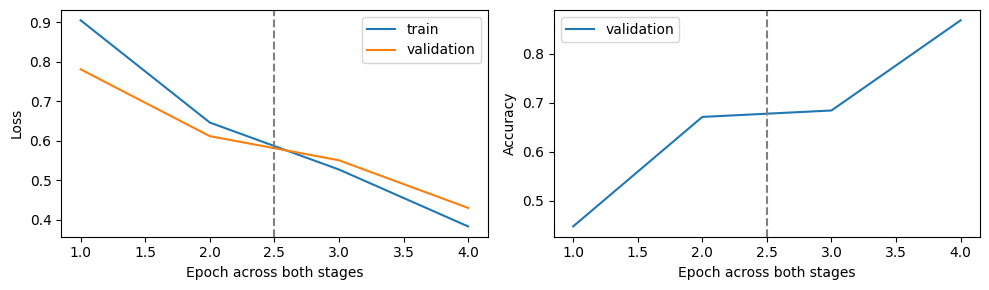

In [8]:
candidates = {
    "head_only": (head_state, head_val),
    "fine_tune": (fine_state, fine_val),
}
selected_stage = min(candidates, key=lambda name: candidates[name][1]["loss"])
selected_state, selected_val = candidates[selected_stage]
model.load_state_dict(selected_state)

for name, metrics in [
    ("random_head", baseline_val),
    ("head_only", head_val),
    ("fine_tune", fine_val),
]:
    print(
        f"{name:12s} validation loss={metrics['loss']:.4f}, "
        f"accuracy={metrics['accuracy']:.1%}"
    )

test_metrics = run_epoch(loaders["test"])
print("Selected by validation:", selected_stage)
print("Final test:", test_metrics)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
steps = range(1, len(history) + 1)
axes[0].plot(steps, [r["train"]["loss"] for r in history], label="train")
axes[0].plot(steps, [r["val"]["loss"] for r in history], label="validation")
axes[0].set_ylabel("Loss")
axes[1].plot(steps, [r["val"]["accuracy"] for r in history], label="validation")
axes[1].set_ylabel("Accuracy")
for axis in axes:
    axis.set_xlabel("Epoch across both stages")
    axis.axvline(HEAD_EPOCHS + 0.5, linestyle="--", color="gray")
    axis.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "learning_curve.png", dpi=150)
plt.show()


## 8. 保存模型、标签和输入规则

state_dict 保存网络参数和 BatchNorm 等层的缓冲状态，需要配合相同架构恢复。类别映射和前处理一起保存，避免换一台机器后解释错误。

这里保存的是用于预测的检查点；若要精确恢复中断训练，还应保存优化器状态、epoch 和随机状态等。PyTorch 的 .pt 文件与 ONNX 的用途不同，扩展名本身不提供通用跨框架执行能力。

In [9]:
input_rules = {
    "color": "RGB",
    "layout": "NCHW",
    "resize_size": preprocess.resize_size[0],
    "crop_size": preprocess.crop_size[0],
    "mean": list(preprocess.mean),
    "std": list(preprocess.std),
    "interpolation": preprocess.interpolation.value,
    "antialias": preprocess.antialias,
}
versions = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "architecture": platform.machine(),
}
checkpoint = {
    "architecture": "resnet18",
    "model_state": {
        name: value.detach().cpu().clone()
        for name, value in model.state_dict().items()
    },
    "class_names": class_names,
    "pretrained_weights": weights.name,
    "input_rules": input_rules,
    "selected_stage": selected_stage,
    "versions": versions,
}
checkpoint_path = OUTPUT_DIR / "ants_bees_resnet18.pt"
torch.save(checkpoint, checkpoint_path)

report = {
    "seed": SEED,
    "config": {
        "batch_size": BATCH_SIZE, "train_per_class": TRAIN_PER_CLASS,
        "head_epochs": HEAD_EPOCHS, "fine_tune_epochs": FINE_TUNE_EPOCHS,
    },
    "class_names": class_names,
    "samples": {name: len(dataset) for name, dataset in split_datasets.items()},
    "validation": {"random_head": baseline_val, "head_only": head_val, "fine_tune": fine_val},
    "selected_stage": selected_stage,
    "test": test_metrics,
    "parameter_checks": {"head_only": head_checks, "fine_tune": fine_checks},
    "history": history,
    "splits": split_manifest,
    "versions": versions,
    "data_scope": "held out from this fine-tuning; upstream ImageNet overlap is possible",
}
(OUTPUT_DIR / "report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Saved:", checkpoint_path)


Saved: outputs/ants_bees_resnet18.pt


## 9. 重新加载，预测一张图片

恢复模型时使用 weights=None，不再下载或加载初始 ImageNet 参数；随后由检查点覆盖全部参数。前处理也从保存的规则重建。

分类得分仍是 logits。只找最高类别可以直接 argmax；展示概率时沿类别轴 softmax。最后检查重新加载前后的输出是否一致。

Reload check: preprocessing and predictions match
True: ants
Predicted: ants
Probability: 0.6465632319450378


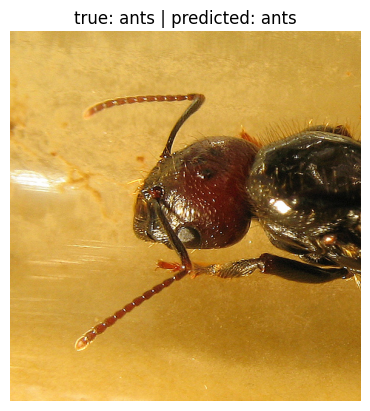

In [10]:
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
restored = models.resnet18(weights=None)
restored.fc = nn.Linear(restored.fc.in_features, len(saved["class_names"]))
restored.load_state_dict(saved["model_state"])
restored.eval()

rules = saved["input_rules"]
restored_preprocess = transforms.Compose([
    transforms.Resize(
        rules["resize_size"],
        interpolation=InterpolationMode(rules["interpolation"]),
        antialias=rules["antialias"],
    ),
    transforms.CenterCrop(rules["crop_size"]),
    transforms.ToTensor(),
    transforms.Normalize(rules["mean"], rules["std"]),
])

image_path, true_label = evaluation_data.samples[int(test_indices[0])]
with Image.open(image_path) as image:
    original_image = image.convert("RGB")
input_tensor = restored_preprocess(original_image).unsqueeze(0)
torch.testing.assert_close(input_tensor[0], preprocess(original_image))

model.eval()
with torch.inference_mode():
    original_logits = model(input_tensor.to(device)).cpu()
    restored_logits = restored(input_tensor)
    torch.testing.assert_close(original_logits, restored_logits)
    probabilities = restored_logits.softmax(dim=1)[0]
    prediction = int(probabilities.argmax())

print("Reload check: preprocessing and predictions match")
print("True:", saved["class_names"][true_label])
print("Predicted:", saved["class_names"][prediction])
print("Probability:", float(probabilities[prediction]))
plt.imshow(original_image)
plt.title(
    f"true: {saved['class_names'][true_label]} | "
    f"predicted: {saved['class_names'][prediction]}"
)
plt.axis("off")
plt.show()


## 10. 如何确认自己理解了微调

先解释这四个问题，再修改参数重跑：

1. 为什么第一阶段训练过了，仍只叫固定特征提取器？第二阶段具体更新了哪组已有参数？
2. 只把 requires_grad 改为 True，却不修改第一阶段的优化器，layer4 会不会更新？
3. 如果微调后的验证集指标变差，应该直接增加 epoch，还是先检查数据量、学习率和错误样本？
4. 为什么新增标签需要训练输出层，不能只向 labels 文件追加文字？

可以尝试使用全部训练图、改变微调轮次，或将 layer3 一并解冻。每次只改一个因素，记录验证表现；保留最终测试边界。重新用测试结果反复选参数后，它就不再是独立的最终评估。

本例的权重变化检查证明代码确实执行了固定/微调；最终指标是否提升要看数据和设置。小数据集与 ImageNet 来源重叠也限制了指标解释。

参考：[PyTorch 迁移学习教程](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)、[ResNet18 权重](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)、[保存与加载](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)。